# 02. Model Training & Evaluation

## Overview
This notebook serves as the main entry point for:
1.  **Verifying the Hardware** (GPU availability).
2.  **Training the ResNet50 Model** (executing the training pipeline).
3.  **Evaluating Performance** using professional diagnostic plots (Confusion Matrix, ROC, Reliability Curves).

## Objectives
-   Confirm CUDA acceleration is active.
-   Train the model on the processed dataset.
-   Assess generalization performance on the validation set.
-   Visualize class-wise metrics and prediction confidence.

In [1]:
# 1. Imports & Setup
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import logging
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Add project root to path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import PROJECT_ROOT, MODELS_DIR, REPORTS_DIR
from src.visualization.plots import (
    set_plot_style,
    plot_learning_curves,
    plot_model_diagnostics,
    plot_confidence_abstention_panel
)

# Configure Styling
set_plot_style()
logger = logging.getLogger(__name__)
logging.basicConfig(level=logging.INFO)

print(f"Project Root: {PROJECT_ROOT}")

Project Root: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection


In [2]:
# 2. Hardware Verification
print(f"PyTorch Version: {torch.__version__}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    device_count = torch.cuda.device_count()
    print(f"SUCCESS: GPU is available!")
    print(f"   Device: {device_name}")
    print(f"   Count: {device_count}")
    print(f"   Cuda Version: {torch.version.cuda}")
else:
    print("\u26A0 WARNING: GPU not detected. Training will be extremely slow on CPU.")
    print("   Please check your environment configuration.")

PyTorch Version: 2.7.1+cu118
SUCCESS: GPU is available!
   Device: NVIDIA RTX 2000 Ada Generation Laptop GPU
   Count: 1
   Cuda Version: 11.8


In [3]:
# 3. Model Selection & Execution
# --------------------------------------------------------------------------
MODEL_NAME = 'resnet50' # 'efficientnet_b3' 'resnet50'
# --------------------------------------------------------------------------

print(f"--> Selected Model: {MODEL_NAME}")

HISTORY_PATH = REPORTS_DIR / f"history_{MODEL_NAME}.joblib"
PREDICTIONS_PATH = REPORTS_DIR / f"predictions_{MODEL_NAME}.csv"

# Check if results exist
if HISTORY_PATH.exists() and PREDICTIONS_PATH.exists():
    print(f"Found existing results for {MODEL_NAME}.")
    print(f"   History: {HISTORY_PATH.name}")
    print(f"   Preds:   {PREDICTIONS_PATH.name}")
else:
    print(f"\u26A0 Results for {MODEL_NAME} not found (or partial). Checking for weights...")
    
    # Check if weights exist
    weights_path = MODELS_DIR / f"{MODEL_NAME}_best.pth"
    
    if weights_path.exists():
        print(f"Found trained weights at {weights_path}")
        print("Running inference generation (skipping training)...")
        # Run inference using the new --evaluate flag
        !python -m src.models.train_model --model {MODEL_NAME} --evaluate --cached --num-workers 4 --batch-size 8
    else:
        print("No trained weights found. Starting FULL TRAINING...")
        !python -m src.models.train_model --model {MODEL_NAME} --cached --num-workers 4 --batch-size 8

    # Validate
    if PREDICTIONS_PATH.exists():
        print("Process finished successfully.")
    else:
        raise RuntimeError(f"Script finished but {PREDICTIONS_PATH.name} was not found! Check terminal for errors.")

--> Selected Model: resnet50
⚠ Results for resnet50 not found (or partial). Checking for weights...
Found trained weights at C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\models\resnet50_best.pth
Running inference generation (skipping training)...
Process finished successfully.


c:\Users\matteucc\AppData\Local\anaconda3\envs\diabetic_retinopathy\python.exe: Error while finding module specification for 'src.models.train_model' (ModuleNotFoundError: No module named 'src.models')


In [4]:
# 4. Evaluation: Load Artifacts & Plot Learning Curves

print(f"Loading Artifacts for: {MODEL_NAME}...")
# Note: HISTORY_PATH and PREDICTIONS_PATH are set in the previous cell.

# Load History
if HISTORY_PATH.exists():
    history = joblib.load(HISTORY_PATH)
    print("Training History Loaded.")
    print(f"Keys: {history.keys()}")
    
    # Quick Summary of Best Epochs
    best_loss_idx = np.argmin(history['val_loss'])
    best_kappa_idx = np.argmax(history.get('val_kappa', [-1]))
    
    print("-" * 30)
    print(f"Best Val Loss:  {history['val_loss'][best_loss_idx]:.4f} (Epoch {best_loss_idx+1})")
    print(f"Best Val Kappa: {history.get('val_kappa', [0])[best_kappa_idx]:.4f} (Epoch {best_kappa_idx+1})")
    print("-" * 30)
    
    # Plot Learning Curves
    plot_learning_curves(
        history, 
        save_folder="evaluation", 
        title_prefix=f"{MODEL_NAME}_"
    )
    plt.show()

else:
    print("ERROR: History file not found.")

# Load Predictions
if PREDICTIONS_PATH.exists():
    preds_df = pd.read_csv(PREDICTIONS_PATH)
    print(f"Predictions Loaded. Shape: {preds_df.shape}")
    display(preds_df.head())
else:
    print("ERROR: Predictions file not found.")

Loading Artifacts for: resnet50...
ERROR: History file not found.
Predictions Loaded. Shape: (5270, 8)


,image_name,true,pred,prob_0,prob_1,prob_2,prob_3,prob_4
0,17_left,0,0,0.786771,0.145883,0.065510,0.001437,3.995567e-04
1,17_right,1,1,0.138255,0.503506,0.336409,0.021256,5.744093e-04
2,25_left,0,0,0.805196,0.167602,0.025628,0.001410,1.638349e-04
3,25_right,0,0,0.790398,0.178955,0.029048,0.001232,3.675036e-04
4,41_left,0,0,0.951211,0.045291,0.003442,0.000055,4.308531e-07



Classification Report:
               precision    recall  f1-score   support

        No DR       0.91      0.92      0.92      3807
         Mild       0.34      0.49      0.40       366
     Moderate       0.73      0.60      0.66       839
       Severe       0.52      0.48      0.50       136
Proliferative       0.64      0.63      0.64       122

     accuracy                           0.82      5270
    macro avg       0.63      0.62      0.62      5270
 weighted avg       0.83      0.82      0.82      5270



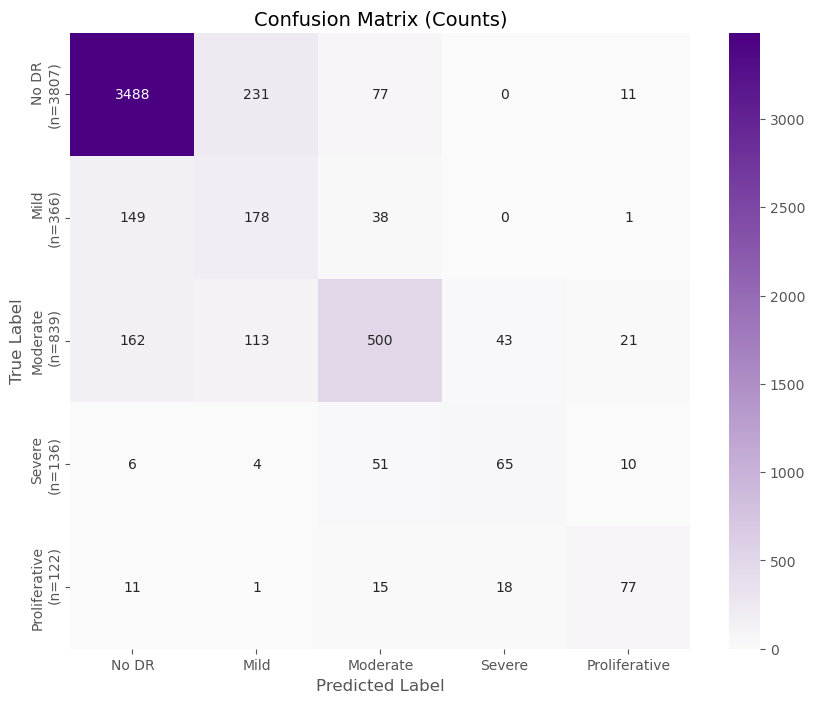

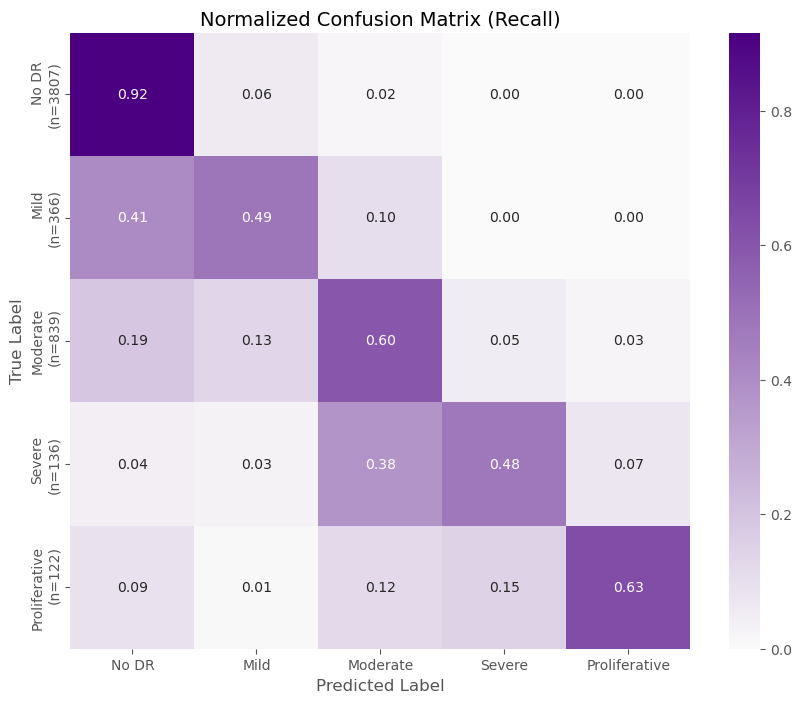

In [5]:
# 6. Confusion Matrix & Detailed Metrics
# Visualize the confusion matrix to see where the model is struggling.

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

if PREDICTIONS_PATH.exists():
    # True Labels vs Predicted Labels
    y_true = preds_df['true']
    y_pred = preds_df['pred']
    
    # Classification Report
    print("\nClassification Report:")
    report = classification_report(y_true, y_pred, target_names=["No DR", "Mild", "Moderate", "Severe", "Proliferative"])
    print(report)
    
    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

    # Calculate counts per class for labeling
    class_counts = cm.sum(axis=1)
    yticklabels_with_counts = [f"{name}\n(n={count})" for name, count in zip(class_names, class_counts)]
    
    # Define custom colormap (Deep Purple as in src/visualization/plots.py)
    cmap_purple = LinearSegmentedColormap.from_list("custom_purple", ["#fafafa", "#4B0082"])
    
    # --- Standardize normalization ---
    # Plot 1: Standard Count
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_purple, 
                xticklabels=class_names,
                yticklabels=yticklabels_with_counts)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix (Counts)')
    plt.show()

    # Plot 2: Row-Normalized (Recall/Sensitivity per class)
    # Allows seeing "Of all Severe cases, what % were classified correctly?"
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap=cmap_purple,
                xticklabels=class_names,
                yticklabels=yticklabels_with_counts)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Normalized Confusion Matrix (Recall)')
    plt.show()

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
c:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\src\visualization\plots.py:343: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=np.arange(n_classes), y=recall, ax=ax_bar, palette=colors)
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Loading predictions from: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\predictions_resnet50.csv
Columns: ['image_name', 'true', 'pred', 'prob_0', 'prob_1', 'prob_2', 'prob_3', 'prob_4']


INFO:src.visualization.plots:Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\resnet50_model_diagnostics.png


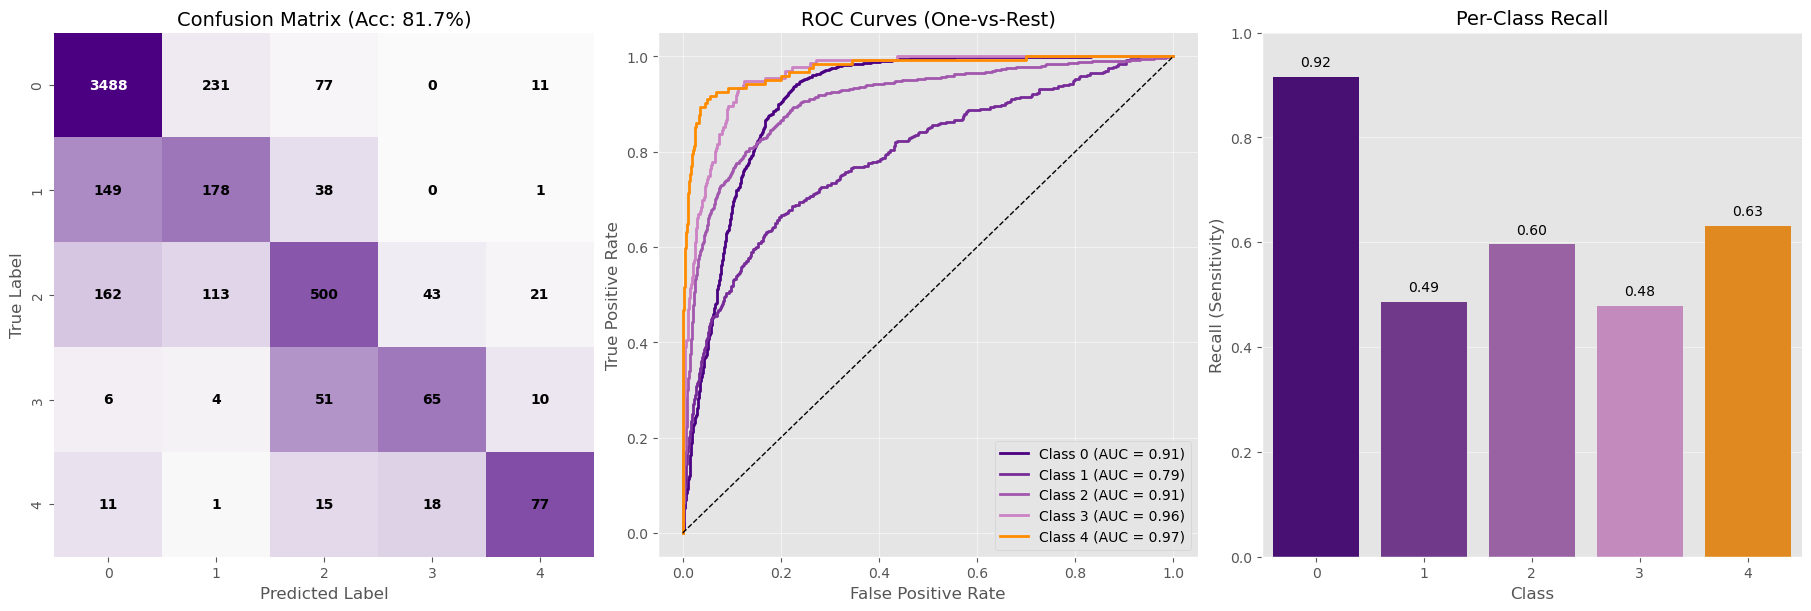

In [6]:
# 5. Diagnostic Panel (Confusion Matrix & ROC)

if PREDICTIONS_PATH.exists():
    print(f"Loading predictions from: {PREDICTIONS_PATH}")
    results_df = pd.read_csv(PREDICTIONS_PATH)
    
    # Ensure columns match expected names
    # train_model.py should output 'image_name', 'true', 'pred', 'prob_0', 'prob_1'...
    print(f"Columns: {results_df.columns.tolist()}")
    
    # Generate Diagnostics
    # We pass title_prefix so the saved file includes the model name (e.g. resnet50_Model_Diagnostics.png)
    plot_model_diagnostics(
        results_df, 
        n_classes=5, 
        save_folder="evaluation", 
        title_prefix=f"{MODEL_NAME}_"
    )
    plt.show()
else:
    print(f"Predictions file not found at {PREDICTIONS_PATH}")

INFO:src.visualization.plots:Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\resnet50_confidence_analysis.png


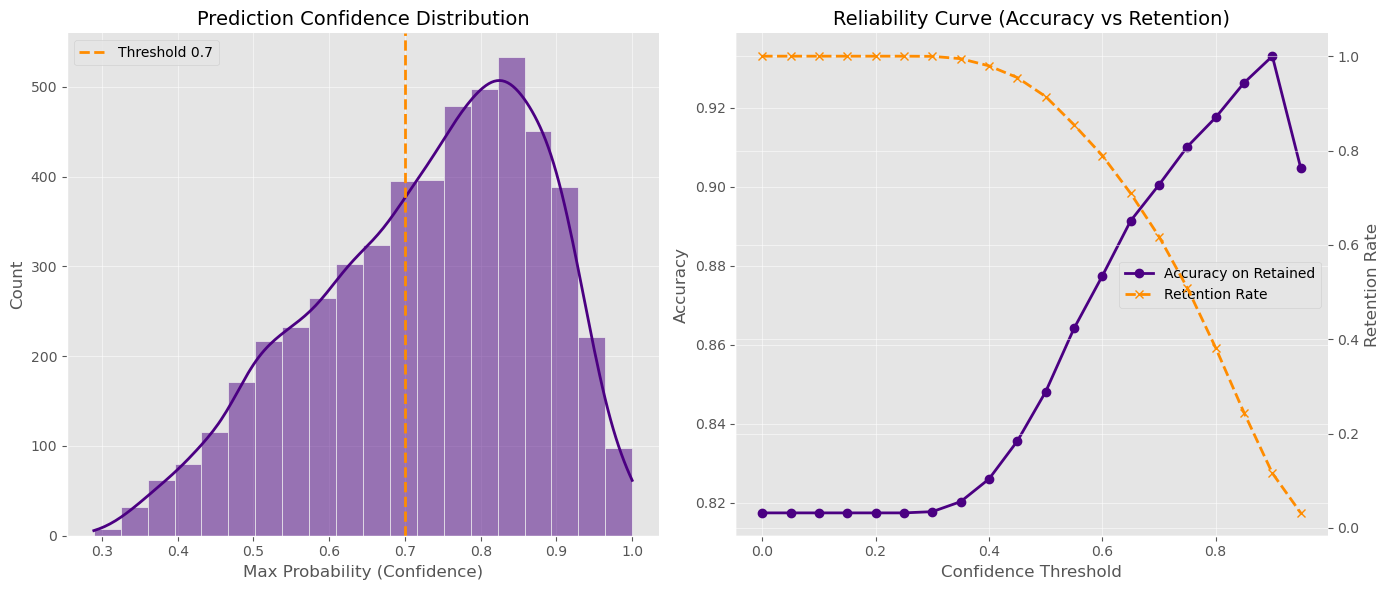

In [7]:
# 6. Reliability & Abstention Analysis

if PREDICTIONS_PATH.exists():
    # Analyze Confidence
    # A threshold of 0.7 means we only classify if max probability > 70%
    plot_confidence_abstention_panel(
        results_df, 
        confidence_threshold=0.7, 
        save_folder="evaluation",
        title_prefix=f"{MODEL_NAME}_"
    )
    plt.show()

Visualizing Error Cases:


INFO:src.visualization.plots:Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\resnet50_failure_analysis.png


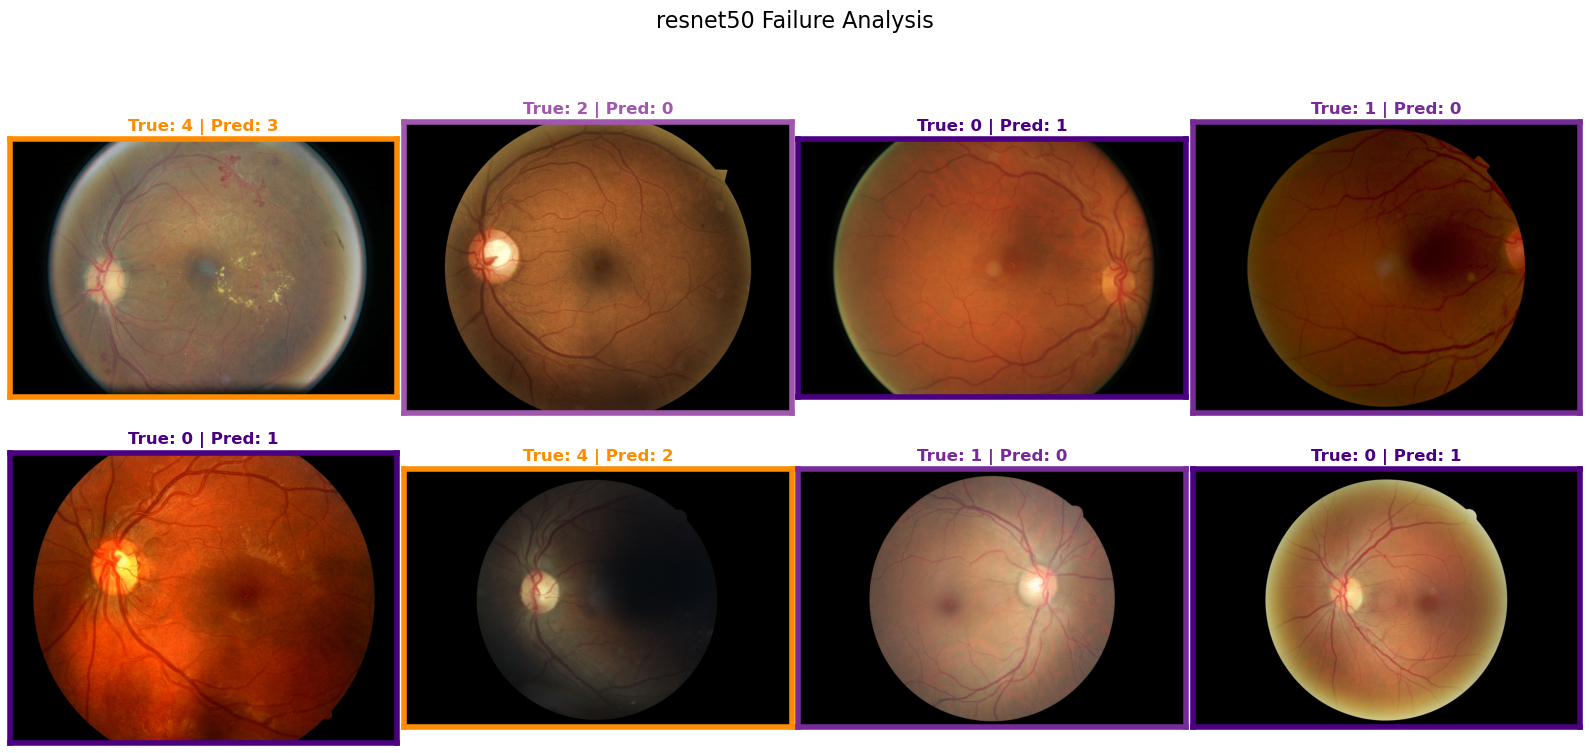

In [8]:
# 7. Sample Predictions Audit
from src.visualization.plots import plot_image_grid
import cv2

# Function to load images based on paths in dataframe (if available) or raw loading
# For demonstration, we just need to load a few images from the test set.

# Note: results_df from train_model.py typically has 'image_name'.
# We need to construct the full path.

if PREDICTIONS_PATH.exists() and 'image_name' in results_df.columns:
    # Construct path (Adjust based on your data structure, e.g. data/train/)
    from src.config import PROCESSED_DATA_DIR, DATA_DIR
    
    # Identify False Predictions
    errors = results_df[results_df['true'] != results_df['pred']]
    
    if len(errors) > 0:
        sample_errors = errors.sample(n=min(8, len(errors)), random_state=42)
        
        images = []
        labels = []
        preds = []
        titles = []
        
        for idx, row in sample_errors.iterrows():
            img_path = DATA_DIR / "train" / f"{row['image_name']}.jpeg"
            if not img_path.exists():
                # Try adding extension or different path
                pass
            
            # Simple load (using opencv or PIL)
            # We use a placeholder logic here assuming path exists
            try:
                img = cv2.imread(str(img_path))
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                images.append(img)
                labels.append(row['true'])
                preds.append(row['pred'])
                titles.append(f"True: {row['true']} | Pred: {row['pred']}")
            except:
                pass
        
        if images:
            print("Visualizing Error Cases:")
            plot_image_grid(
                images, 
                labels, 
                preds=preds, 
                titles=titles, 
                title=f"{MODEL_NAME} Failure Analysis", 
                save_folder="evaluation"
            )
            plt.show()
    else:
        print("Model has 100% accuracy! No errors to visualize.")